In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

df = pd.read_csv('compras_ecommerce.csv')
df_copy = df
display(df.head())

,ID_Transaccion,Producto
0,TKT-00181,Teclado Mecánico RGB
1,TKT-01162,"Monitor 27"" 144Hz"
2,TKT-00840,Silla Gamer Ergonómica
3,TKT-01734,silla gamer ergonómica
4,TKT-01899,Mousepad XL


In [2]:
df = df.dropna()
df['Producto'] = df['Producto'].str.upper()
df = df[df["ID_Transaccion"] != "ERR_TIMEOUT"]
df = df.drop_duplicates(subset=['ID_Transaccion', 'Producto'], keep='last')
df_copy = df.copy()

In [3]:
df = df.merge(df_copy, on=['ID_Transaccion'], how='left')
df = df[df['Producto_x'] < df['Producto_y']]
interacciones = df.groupby(['Producto_x', 'Producto_y']).size().reset_index(name='Peso').reset_index(drop=True)
display(interacciones)

,Producto_x,Producto_y,Peso
0,AUDÍFONOS BLUETOOTH,CABLE HDMI 2.1,21
1,AUDÍFONOS BLUETOOTH,LAPTOP PRO 15,341
2,AUDÍFONOS BLUETOOTH,MICRÓFONO DE CONDENSADOR,21
3,AUDÍFONOS BLUETOOTH,"MONITOR 27"" 144HZ",20
4,AUDÍFONOS BLUETOOTH,MOUSE INALÁMBRICO,334
5,AUDÍFONOS BLUETOOTH,MOUSEPAD XL,23
6,AUDÍFONOS BLUETOOTH,SILLA GAMER ERGONÓMICA,17
7,AUDÍFONOS BLUETOOTH,TECLADO MECÁNICO RGB,26
8,AUDÍFONOS BLUETOOTH,WEBCAM 1080P,364
9,CABLE HDMI 2.1,LAPTOP PRO 15,25


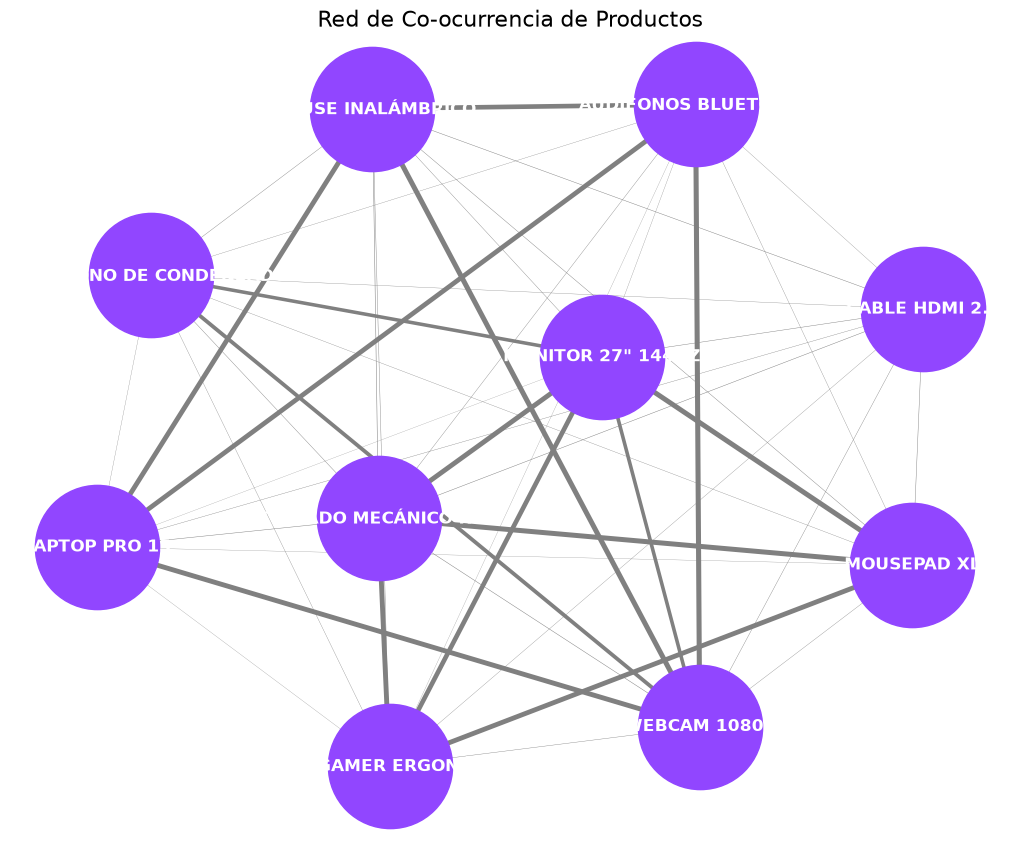

In [ ]:
G_tech = nx.from_pandas_edgelist(interacciones, source='Producto_x', target='Producto_y', edge_attr='Peso', create_using=nx.Graph())

plt.figure(figsize=(10,8))
pos = nx.spring_layout(G_tech, seed=42)
pesos = [d['Peso']*0.01 for (u, v, d) in G_tech.edges(data=True)]
nx.draw(G_tech, pos, with_labels=True, node_color='#9146FF', node_size=8000, font_color='white', font_weight='bold', width=pesos, edge_color='gray')
plt.title('Red de Co-ocurrencia de Productos', fontsize=16)
plt.show()

In [ ]:
print("Degree Centrality:", nx.degree_centrality(G_tech))
print("Grado con Pesos (Fuerza):", dict(G_tech.degree(weight='Peso')))

Degree Centrality: {'AUDÍFONOS BLUETOOTH': 1.0, 'CABLE HDMI 2.1': 1.0, 'LAPTOP PRO 15': 1.0, 'MICRÓFONO DE CONDENSADOR': 1.0, 'MONITOR 27" 144HZ': 1.0, 'MOUSE INALÁMBRICO': 1.0, 'MOUSEPAD XL': 1.0, 'SILLA GAMER ERGONÓMICA': 1.0, 'TECLADO MECÁNICO RGB': 1.0, 'WEBCAM 1080P': 1.0}
Grado con Pesos (Fuerza): {'AUDÍFONOS BLUETOOTH': 1167, 'CABLE HDMI 2.1': 246, 'LAPTOP PRO 15': 1170, 'MICRÓFONO DE CONDENSADOR': 697, 'MONITOR 27" 144HZ': 1648, 'MOUSE INALÁMBRICO': 1226, 'MOUSEPAD XL': 1214, 'SILLA GAMER ERGONÓMICA': 1167, 'TECLADO MECÁNICO RGB': 1252, 'WEBCAM 1080P': 1721}


In [ ]:
vecinos = G_tech['TECLADO MECÁNICO RGB']
recomendacion = max(vecinos, key=lambda n: vecinos[n]['Peso'])
print(f"Producto a recomendar: {recomendacion} ({vecinos[recomendacion]['Peso']} veces comprado juntos)")

Producto a recomendar: MOUSEPAD XL (359 veces comprado juntos)
